# Homework 5: Statistical Hypothesis Testing (Chi-Square & ANOVA)


## Dataset Setup Instructions

To complete this assignment, download **IBM HR Analytics Employee Attrition & Performance Dataset** from github or kaggle.


### Part 1: Chi-Square Test of Independence (Categorical vs. Categorical)
1. Formulate a research question examining whether two workforce attributes are associated (e.g., *Is an employee's Department associated with their likelihood of working OverTime? Is Gender associated with different Job Roles?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Compute a contingency table showing the exact cross-tabulated counts of employees across these categories.
4. Execute a Chi-Square Test of Independence at a 5% significance level ($\alpha = 0.05$). Report the test statistic, degrees of freedom, and the p-value.
5. Create a grouped or stacked bar chart to visually compare the proportional distribution between the groups.
6. Write 2–3 sentences interpreting what these findings mean for an HR manager trying to address workplace imbalances.

---

### Part 2: One-Way ANOVA (Numerical Continuous vs. Categorical with >2 Groups)
1. Formulate a research question evaluating whether average compensation scales vary across different structural groups (e.g., *Does the mean MonthlyIncome differ significantly across the 3 distinct Departments? Does it differ based on MaritalStatus?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Run a One-Way ANOVA test at a 5% significance level ($\alpha = 0.05$). Report the F-statistic and the p-value.
4. Generate a boxplot or violin plot displaying `MonthlyIncome` across the different categorical groups.
5. Write 2–3 sentences interpreting your statistical conclusions. If the test is significant, note which specific groups appear to stand out.

---

## Part 3: Assessing Decision Errors in HR Policy
Select **either** your Chi-Square test or your ANOVA test from Part 1 or 2. For that specific test, write a brief analysis detailing:
1. Exactly what a Type I error (false positive) translates to in the context of your specific workplace hypothesis.
2. Exactly what a Type II error (false negative) translates to in the context of your specific workplace hypothesis.
3. From a corporate governance, budget planning, or employee retention standpoint, explain which of these two errors carries a worse operational risk for the company, and why.



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, f_oneway

**Research Question:** Is there a statistically significant association between Department and OverTime?

**Null Hypothesis (H0):** There is no association between Department and OverTime.

**Alternative Hypothesis (H1):** There is an association between Department and OverTime.

**Significance Level:** α = 0.05


In [3]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:

contingency_table = pd.crosstab(df['Department'], df['OverTime'])

contingency_table


OverTime,No,Yes
Department,,
Human Resources,46,17
Research & Development,690,271
Sales,318,128


In [6]:
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)


Chi-Square Statistic: 0.09360659979986957
P-value: 0.9542750851354225
Degrees of Freedom: 2


### Report 

The Chi-Square Test of Independence was performed to determine whether there is a statistically significant association between Department and OverTime.

The results showed a Chi-Square statistic of 0.0936, a p-value of 0.9543, and 2 degrees of freedom.

Since the p-value is greater than the significance level of 0.05, we fail to reject the null hypothesis.

There is not enough statistical evidence to conclude that an employee's department is associated with whether they work overtime.

In [7]:
overtime_percent = pd.crosstab(
    df['Department'],
    df['OverTime'],
    normalize='index'
) * 100

overtime_percent


OverTime,No,Yes
Department,,
Human Resources,73.015873,26.984127
Research & Development,71.800208,28.199792
Sales,71.300448,28.699552


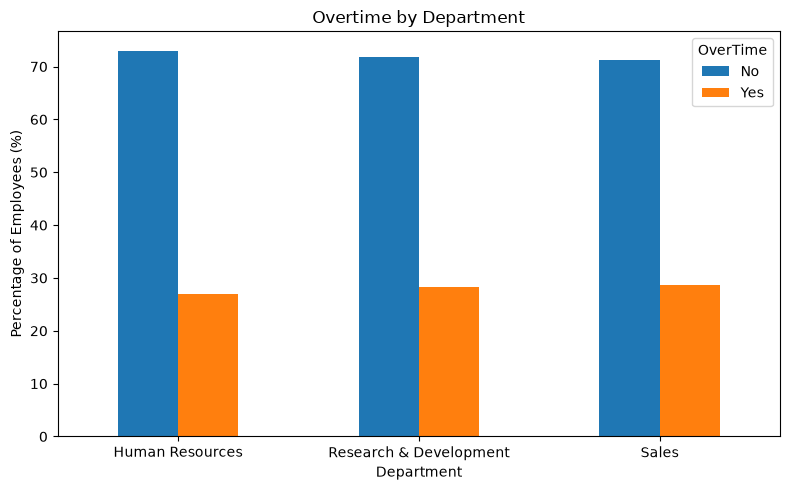

In [10]:
overtime_percent.plot(kind='bar', figsize=(8, 5))

plt.title('Overtime by Department')
plt.xlabel('Department')
plt.ylabel('Percentage of Employees (%)')
plt.legend(title='OverTime')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Conclusion
The bar chart shows that overtime percentages are similar across departments, ranging from approximately 27.0% in Human Resources to 28.7% in Sales. Since the Chi-Square test produced a p-value of 0.9543, which is greater than 0.05, we fail to reject the null hypothesis and find no statistically significant association between department and overtime status. HR could investigate other factors, such as job roles and workloads, to better understand overtime patterns.

**Part 2 Report**

 **Research Question** Is there a statistically significant difference in average monthly income among employees in different departments?
 
**Null Hypothesis (H0):** The average monthly income is equal across Human Resources, Research & Development, and Sales.

**Alternative Hypothesis (H1):** At least one department has a different average monthly income.

**Significance Level:** α = 0.05

In [11]:
average_income = df.groupby('Department')['MonthlyIncome'].mean()

average_income


Department
Human Resources           6654.507937
Research & Development    6281.252862
Sales                     6959.172646
Name: MonthlyIncome, dtype: float64

In [12]:
hr = df[df['Department'] == 'Human Resources']['MonthlyIncome']

rd = df[df['Department'] == 'Research & Development']['MonthlyIncome']

sales = df[df['Department'] == 'Sales']['MonthlyIncome']

f_stat, p_value_anova = f_oneway(hr, rd, sales)

print("F-statistic:", f_stat)
print("P-value:", p_value_anova)


F-statistic: 3.201782929420172
P-value: 0.04097409724987054


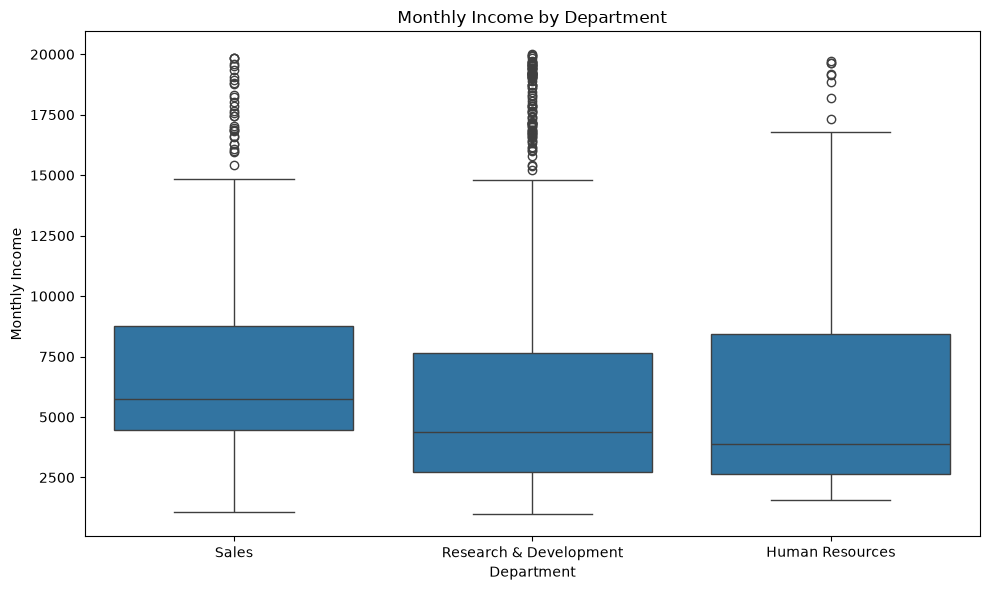

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='Department', y='MonthlyIncome')

plt.title('Monthly Income by Department')
plt.xlabel('Department')
plt.ylabel('Monthly Income')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Statistical Conclusion

To find out if average monthly income differs between Human Resources, Research & Development, and Sales, a one-way ANOVA was used. The test resulted in an F-statistic of 3.2018 and a p-value of 0.0410, so we reject the null hypothesis because the p-value is less than 0.05. This means that at least one department has a different average monthly income, with Sales having the highest observed average ($6,959.17) and Research & Development having the lowest ($6,281.25).

## Part 3: Type I and Type II

### Type I Error (False Positive)

A Type I error in an ANOVA test is when we conclude that the average monthly income is different between departments when in fact the means are the same. It might cause the company to spend money on investigating or changing salary policies.

### Type II Error (False Negative)

A Type II error in an ANOVA test would happen if we concluded that there was not enough evidence of a salary difference when there actually was a difference between departments. This could cause HR to overlook important salary differences that might affect employee satisfaction and retention.

### Which Error Is Worse?

I think a Type II error would be worse for the company because it could cause HR to miss important salary differences between departments. If these differences are not looked into, the employees might become unhappy with their compensation, which could lead to higher turnover and additional hiring costs. A Type I error could waste company resources, but a Type II error could allow real problems to go unnoticed for a long time.